**15.071 The AI Edge** · Project 1: Predictive AI · Fall 2026 · MIT Sloan School of Management

Team: Audrey DeVault, Paul Bustarret, Charles Loriot, Sara Alafifi

---

# Late fusion: does the opposition record improve the tabular model?

The two earlier notebooks each built one half of the model:

| Notebook | Model | Out-of-sample scores for 2015–2018 entries |
|---|---|---|
| [01_charles_tabular_models](01_charles_tabular_models.ipynb) | LASSO and gradient boosting on entry-time project, county and POI features | Fit on 2005–2014 entries, scored out of time |
| [02_paul_text_models](02_paul_text_models.ipynb) | Fine-tuned DistilBERT reads Sabin Center paragraphs; a county-history model turns them into `p_text` | Rolling: each year scored by a model fit on earlier years (`data/processed/text_scores.csv`) |

This notebook **merges them with late fusion**: each model scores a project on its own, and a small second-stage model learns how to combine the two scores. The question is the one the deep-learning half has to answer for the project: **does reading the opposition record add anything the tabular model doesn't already know?**

Nothing here touches the 2019–2020 test cohort.

## Setup

Runs locally in the project `.venv`. No GPU or PyTorch is needed: the text model's scores were computed on Colab and saved to `data/processed/text_scores.csv`.

In [1]:
import os, sys, warnings
from pathlib import Path

# The project root is the folder holding pyproject.toml, found by walking up
# from wherever this notebook is opened.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
print("Project folder:", ROOT)

Project folder: /Users/paulbustarret/Documents/MIT/ai-edge/Final Project/queue-risk-ai


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

from queue_risk import config, data, evaluate, text
from queue_risk.stack import STAGE1, _stage1, bootstrap_gain, leave_one_year_out

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
SEED = config.SEED
YEARS = [2015, 2016, 2017, 2018]

## The two inputs

**Tabular.** `stack._stage1` refits each model at the settings the pipeline selected, on all 2005–2014 entries, and returns its log-odds for every project. For 2015–2018 entries these are the same out-of-time scores as notebook 01's "harder check" section.

**Text.** `text_scores.csv` holds one row per 2015–2018 project: `p_text` from the selected county-history model (*Counts*), and `has_text`, which flags the projects whose county had an earlier contested project.

We join on `project_id` and check that the two files agree on the outcome.

In [3]:
raw = data.load_raw_queue()
projects = data.built_within(raw, config.HORIZON)
T = text.load_text_scores()
assert T is not None, "Run notebooks/02_paul_text_models.ipynb first (it writes data/processed/text_scores.csv)."

V = T[["project_id", "q_year", "y", "has_text", "p_text"]].copy()
for s1 in STAGE1:                                   # "lasso", "gb"
    logit, y = _stage1(raw, projects, s1)
    tab = projects[["project_id"]].assign(**{f"logit_{s1}": logit, f"y_{s1}": y})
    V = V.merge(tab, on="project_id", how="left", validate="1:1")
    assert V[f"logit_{s1}"].notna().all(), f"{s1}: some text rows have no tabular score"
    assert (V["y"] == V[f"y_{s1}"]).all(), f"{s1}: outcomes disagree between the two files"
    V = V.drop(columns=f"y_{s1}")

V = V.merge(projects[["project_id", "mw_total", "region", "type_1"]], on="project_id", how="left")
p = V["p_text"].clip(1e-6, 1 - 1e-6)
V["logit_text"] = np.log(p / (1 - p))
V["text_x_cov"] = V["has_text"] * V["logit_text"]   # the text score where a county record exists

print(f"Joined {len(V):,} of {len(T):,} text rows; every one has both scores and matching outcomes.")
V.groupby("q_year").agg(projects=("y", "size"), built_5y=("y", "mean"), has_text=("has_text", "mean"))

Joined 3,490 of 3,490 text rows; every one has both scores and matching outcomes.


,projects,built_5y,has_text
q_year,,,
2015,550,0.145,0.124
2016,905,0.103,0.114
2017,963,0.077,0.089
2018,1072,0.057,0.084


## How the fusion works

**Stacking on log-odds** (Lecture 7). For each 2015–2018 project we have two scores that were produced without seeing that project's year. A logistic regression on the two log-odds learns how much weight each deserves:

$$\text{logit}\,P(\text{built}) = a + b_1\,\text{logit}(p_{tab}) + b_2\,\text{logit}(p_{text})$$

An equal-weight average would be the wrong default here: the text score is close to a coin flip on its own, so averaging would mostly add noise. The second stage can also give it a weight near zero if it carries nothing.

**Fit leave-one-year-out**, as `stack.py` does: each year's fused scores come from a second stage fit on the other three years. Three or four coefficients barely overfit, but because this borrows later years we also run a strictly **rolling** check (fit on earlier years only) further down.

**Metric: AUC within each entry year, averaged.** The fund ranks projects inside a cohort. A pooled AUC across years also rewards getting each year's base rate right, and a second stage refit per year shifts those intercepts around, which muddies the comparison. Within-year AUC is what notebook 02 used too.

**The ladder.** Every row is scored the same way, so they can be compared directly:

| Row | Second-stage inputs |
|---|---|
| Tabular only | logit(p_tab), the tabular model recalibrated, the baseline |
| Text only | p_text as is |
| Tabular + opposition flag | logit(p_tab), has_text. This is `stack.py`'s test, here with the re-dated paragraphs |
| **Late fusion** | logit(p_tab), logit(p_text) |
| Late fusion + coverage interaction | adds has_text and has_text × logit(p_text), so the text can count only where a county record exists |
| Rank average (no fitting) | mean of the two within-year percentile ranks |

In [4]:
def within_year_auc(y, s, years):
    y, s, years = np.asarray(y), np.asarray(s), np.asarray(years)
    return {t: roc_auc_score(y[years == t], s[years == t]) for t in YEARS}


def rank_average(V, a, b):
    r = lambda c: V.groupby("q_year")[c].rank(pct=True)
    return ((r(a) + r(b)) / 2).to_numpy()


def ladder_rows(s1):
    tab = f"logit_{s1}"
    return {
        "Tabular only": [tab],
        "Text only": None,                                        # p_text as is
        "Tabular + opposition flag": [tab, "has_text"],
        "Late fusion": [tab, "logit_text"],
        "Late fusion + coverage interaction": [tab, "logit_text", "has_text", "text_x_cov"],
        "Rank average (no fitting)": "rank",
    }


def score_ladder(s1):
    out = {}
    for name, cols in ladder_rows(s1).items():
        if cols is None:
            out[name] = V["p_text"].to_numpy()
        elif cols == "rank":
            out[name] = rank_average(V, f"logit_{s1}", "logit_text")
        else:
            out[name] = leave_one_year_out(V, cols)
    return out


yy, yrs = V["y"].to_numpy(), V["q_year"].to_numpy()
cov = V["has_text"].to_numpy() == 1
scores, tables = {}, {}
for s1 in STAGE1:
    scores[s1] = score_ladder(s1)
    rows = []
    for name, s in scores[s1].items():
        wy = within_year_auc(yy, s, yrs)
        rows.append({"row": name, "mean within-year AUC": np.mean(list(wy.values())), **wy,
                     "pooled AUC": roc_auc_score(yy, s),
                     "AUC where county has text": roc_auc_score(yy[cov], s[cov])})
    tables[s1] = pd.DataFrame(rows).set_index("row")

for s1 in STAGE1:
    display(Markdown(f"**Stage 1: {STAGE1[s1]}**"))
    display(tables[s1].round(3))

**Stage 1: LASSO logistic**

,mean within-year AUC,2015,2016,2017,2018,pooled AUC,AUC where county has text
row,,,,,,,
Tabular only,0.632,0.611,0.622,0.611,0.685,0.629,0.670
Text only,0.526,0.558,0.523,0.512,0.510,0.558,0.555
Tabular + opposition flag,0.642,0.629,0.631,0.620,0.686,0.636,0.659
Late fusion,0.643,0.631,0.632,0.620,0.689,0.638,0.654
Late fusion + coverage interaction,0.642,0.630,0.632,0.620,0.685,0.635,0.650
Rank average (no fitting),0.640,0.638,0.628,0.612,0.680,0.637,0.691


**Stage 1: Gradient boosting**

,mean within-year AUC,2015,2016,2017,2018,pooled AUC,AUC where county has text
row,,,,,,,
Tabular only,0.605,0.594,0.631,0.556,0.640,0.601,0.572
Text only,0.526,0.558,0.523,0.512,0.510,0.558,0.555
Tabular + opposition flag,0.608,0.608,0.638,0.554,0.632,0.603,0.554
Late fusion,0.611,0.609,0.639,0.556,0.640,0.607,0.575
Late fusion + coverage interaction,0.608,0.608,0.638,0.556,0.631,0.600,0.570
Rank average (no fitting),0.612,0.618,0.635,0.556,0.639,0.614,0.583


Selected fusion (best mean within-year AUC with LASSO logistic as stage 1): Late fusion


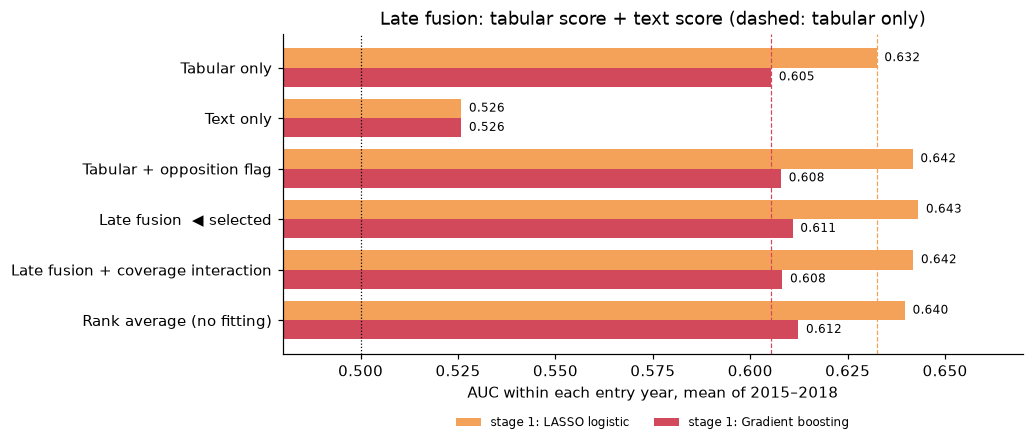

In [5]:
FUSION_ROWS = ["Tabular + opposition flag", "Late fusion", "Late fusion + coverage interaction",
               "Rank average (no fitting)"]
HEAD = "lasso"                     # the headline tabular model (docs/model_log.md, Nov 15)
BEST = tables[HEAD].loc[FUSION_ROWS, "mean within-year AUC"].idxmax()
print(f"Selected fusion (best mean within-year AUC with {STAGE1[HEAD]} as stage 1): {BEST}")

names = list(tables[HEAD].index)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
h = 0.38
ys = np.arange(len(names))[::-1]
for j, (s1, color) in enumerate([("lasso", "#f4a259"), ("gb", "#d1495b")]):
    vals = tables[s1].loc[names, "mean within-year AUC"]
    bars = ax.barh(ys + (0.5 - j) * h, vals, h, color=color, label=f"stage 1: {STAGE1[s1]}")
    for yv, v in zip(ys + (0.5 - j) * h, vals):
        ax.text(v + 0.002, yv, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(ys, [n + ("  ◀ selected" if n == BEST else "") for n in names])
ax.axvline(0.5, color="black", lw=0.8, ls=":")
for s1, color in [("lasso", "#f4a259"), ("gb", "#d1495b")]:
    ax.axvline(tables[s1].loc["Tabular only", "mean within-year AUC"], color=color, lw=0.8, ls="--")
ax.set_xlim(0.48, 0.67)
ax.set_xlabel("AUC within each entry year, mean of 2015–2018")
ax.set_title("Late fusion: tabular score + text score (dashed: tabular only)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "10_fusion_ladder.png", bbox_inches="tight")
plt.show()

**Reading the ladder:**

- **The text on its own is barely above a coin flip** (0.526), as notebook 02 found.
- **Next to the tabular score, it helps a little.** With the LASSO as stage 1, late fusion lifts mean within-year AUC from 0.632 to 0.643, and it is up in every year:
  - 2015: +0.020
  - 2016: +0.010
  - 2017: +0.009
  - 2018: +0.004

  With gradient boosting, the AUC goes from 0.605 to 0.611.
- **Most of the gain is already in the simplest signal**: whether the county has seen an earlier contested project (the flag row, 0.642). The reader-based score adds about 0.001 on top. This matches notebook 02: what predicts a new project is that the county had a fight, not how the fight ended.
- **Letting the text count only where a county record exists** (the interaction row) doesn't help. The two extra weights cost more than they bring.
- **The rank average needs no fitting and does about as well.** So the result doesn't depend on the stacking model.

### What the fused model learned

The selected second stage refit on all four years, with coefficients shown as odds ratios. Both inputs are log-odds, so a coefficient of 1 on the tabular score means its probabilities are trusted as they are.

In [6]:
cols = ladder_rows(HEAD)[BEST]
if isinstance(cols, list):
    m = LogisticRegression(max_iter=1000).fit(V[cols], V["y"])
    coef = pd.DataFrame({"coefficient": m.coef_[0], "odds ratio per unit": np.exp(m.coef_[0])}, index=cols)
    sd = V[cols].std()
    coef["odds ratio per 1 SD"] = np.exp(m.coef_[0] * sd.to_numpy())
    display(coef.round(3))
else:
    print("The selected row has no fitted weights (rank average).")

,coefficient,odds ratio per unit,odds ratio per 1 SD
logit_lasso,0.464,1.590,2.797
logit_text,0.461,1.585,1.215


The two log-odds get almost the same weight per unit (about 0.46 each). But the tabular score varies far more across projects:

- **Per standard deviation:** moving one SD on the tabular score multiplies the odds of a build by about 2.8, while one SD on the text score multiplies them by about 1.2.
- **Shrinkage:** a weight below 1 on the tabular score means the second stage pulls its probabilities toward the base rate. That's the out-of-time drift from notebook 01: the 2005–2014 model ranks with more confidence than 2015–2018 outcomes support.

## Is the gain real?

Two bootstraps on the 3,490 projects, 1,000 draws each:

- **Within-year**, the headline. Projects are resampled inside each entry year, and the gain is the change in mean within-year AUC.
- **Pooled**, `stack.bootstrap_gain`, as reported by `stack.py`.

Each fusion row is compared with *Tabular only* for the same stage-1 model.

In [7]:
def bootstrap_within_year_gain(y, a, b, years, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = {t: np.flatnonzero(years == t) for t in YEARS}
    d = []
    for _ in range(n):
        g = []
        for t, ii in idx.items():
            i = rng.choice(ii, len(ii))
            if y[i].min() == y[i].max():
                break
            g.append(roc_auc_score(y[i], b[i]) - roc_auc_score(y[i], a[i]))
        else:
            d.append(np.mean(g))
    d = np.array(d)
    return d.mean(), np.quantile(d, 0.025), np.quantile(d, 0.975), (d > 0).mean()


gain_rows = []
for s1 in STAGE1:
    base = scores[s1]["Tabular only"]
    for name in FUSION_ROWS:
        w = bootstrap_within_year_gain(yy, base, scores[s1][name], yrs)
        p = bootstrap_gain(yy, base, scores[s1][name])
        gain_rows.append({"stage 1": STAGE1[s1], "row": name,
                          "within-year gain": w[0], "95% CI": f"[{w[1]:+.3f}, {w[2]:+.3f}]", "P(gain > 0)": w[3],
                          "pooled gain": p[0], "pooled 95% CI": f"[{p[1]:+.3f}, {p[2]:+.3f}]"})
gains = pd.DataFrame(gain_rows).set_index(["stage 1", "row"])
gains.round(3)

within-year gain            95% CI  P(gain > 0)  pooled gain     pooled 95% CI
stage 1           row                                                                                                               
LASSO logistic    Tabular + opposition flag                      0.009  [-0.000, +0.018]        0.970        0.007  [-0.003, +0.015]
                  Late fusion                                    0.011  [+0.002, +0.019]        0.989        0.009  [+0.001, +0.018]
                  Late fusion + coverage interaction             0.010  [-0.000, +0.019]        0.969        0.006  [-0.003, +0.015]
                  Rank average (no fitting)                      0.008  [-0.006, +0.020]        0.884        0.008  [-0.008, +0.021]
Gradient boosting Tabular + opposition flag                      0.003  [-0.009, +0.013]        0.699        0.002  [-0.008, +0.011]
                  Late fusion                                    0.006  [-0.003, +0.013]        0.910        0.005  [-0.002, +0.013]
                  Late fusion + coverage interaction             0.003  [-0.009, +0.013]        0.719       -0.001  [-0.010, +0.008]
                  Rank average (no fitting)                      0.007  [-0.004, +0.017]        0.898        0.013  [+0.002, +0.023]

**Reading it:**

- **With the LASSO, late fusion is the only row whose interval clears zero on both bootstraps:** +0.011 within year, 95% CI [+0.002, +0.019], positive in 99% of draws. The flag alone is borderline (+0.009, [−0.000, +0.018]).
- **With gradient boosting, nothing clears zero within year.** Late fusion reaches +0.006, positive in 91% of draws.
- **This is a small but consistent gain, not a large one.**
- **The dating fix matters.** `stack.py` reports a larger flag gain (+0.014 pooled) because it still uses the footnote-contaminated paragraph dates. With the re-dated paragraphs, the same flag gives +0.007 pooled. Part of the earlier gain came from the dates.

### A stricter check: rolling second stage

Leave-one-year-out lets the 2015 weights borrow from 2016–2018. Here the second stage only ever sees **earlier** years: fit on 2015 and score 2016, fit on 2015–2016 and score 2017, and so on. That leaves three scored years, and nothing in the pipeline looks ahead.

In [8]:
def rolling_stage2(cols, years=YEARS[1:]):
    s = np.full(len(V), np.nan)
    for t in years:
        fit, held = (V["q_year"] < t).to_numpy(), (V["q_year"] == t).to_numpy()
        m = LogisticRegression(max_iter=1000).fit(V.loc[fit, cols], V["y"][fit])
        s[held] = m.predict_proba(V.loc[held, cols])[:, 1]
    return s


roll_rows = []
for s1 in STAGE1:
    r = {name: rolling_stage2(c) for name, c in ladder_rows(s1).items() if isinstance(c, list)}
    for name, s in r.items():
        wy = {t: roc_auc_score(yy[yrs == t], s[yrs == t]) for t in YEARS[1:]}
        roll_rows.append({"stage 1": STAGE1[s1], "row": name, **wy, "mean 2016–2018": np.mean(list(wy.values()))})
roll = pd.DataFrame(roll_rows).set_index(["stage 1", "row"])
roll["gain vs. tabular only"] = roll["mean 2016–2018"] - roll.groupby(level=0)["mean 2016–2018"].transform("first")
roll.round(3)

2016   2017   2018  mean 2016–2018  gain vs. tabular only
stage 1           row                                                                                           
LASSO logistic    Tabular only                        0.622  0.611  0.685           0.639                  0.000
                  Tabular + opposition flag           0.631  0.612  0.686           0.643                  0.004
                  Late fusion                         0.630  0.619  0.689           0.646                  0.006
                  Late fusion + coverage interaction  0.629  0.614  0.685           0.643                  0.003
Gradient boosting Tabular only                        0.631  0.556  0.640           0.609                  0.000
                  Tabular + opposition flag           0.633  0.554  0.632           0.606                 -0.003
                  Late fusion                         0.634  0.555  0.640           0.610                  0.001
                  Late fusion + coverage interaction  0.633  0.554  0.631           0.606                 -0.003

**With only earlier years to learn from, the gain shrinks:**

- **LASSO:** late fusion adds +0.006 over 2016–2018 (0.639 → 0.646), and it is still the best row.
- **Gradient boosting:** it adds +0.001, which is nothing.

The text's contribution holds up, but it is small and depends on the stage-1 model. It helps the LASSO, the model that transfers best, and barely moves gradient boosting.

## Where does the text change the ranking?

The text model can only speak about the ~10% of projects whose county has an earlier contested project. Everywhere else `p_text` is the same number for every project in a year, so the fusion can't reorder them. So we look at that slice on its own.

In [9]:
sel = scores[HEAD][BEST]
seg = []
for label, m in [("county has earlier contested project", cov), ("no county record", ~cov)]:
    seg.append({"segment": label, "projects": m.sum(), "built within 5y": yy[m].mean(),
                "AUC tabular only": roc_auc_score(yy[m], scores[HEAD]["Tabular only"][m]),
                f"AUC {BEST.lower()}": roc_auc_score(yy[m], sel[m]),
                "mean P tabular only": scores[HEAD]["Tabular only"][m].mean(),
                f"mean P {BEST.lower()}": sel[m].mean()})
pd.DataFrame(seg).set_index("segment").round(3)

,projects,built within 5y,AUC tabular only,AUC late fusion,mean P tabular only,mean P late fusion
segment,,,,,,
county has earlier contested project,347,0.052,0.670,0.654,0.087,0.054
no county record,3143,0.092,0.625,0.626,0.090,0.094


**The gain comes from moving a whole group.**

- **Across groups:** projects in counties with earlier opposition are built at 5.2% within 5 years, against 9.2% elsewhere. The fusion cuts their mean predicted probability from 8.7% to 5.4%, which pulls them down relative to everyone else. That's what lifts the cohort-wide AUC.
- **Within the contested group, the ranking gets slightly worse** (0.670 → 0.654). The tabular model was already ordering those projects reasonably well. The text score, which mostly counts disputes, reshuffles them on a weaker signal.

### Swap analysis: which projects does the text move in or out of the shortlist?

As in notebook 01, the fund backs the **top 25 projects of each cohort**. Comparing the tabular-only shortlist with the fused one shows what the text actually changes: how many projects swap, whether they come from contested counties, and whether the swaps were right.

In [10]:
K = 25
swap_rows, swapped = [], []
for t in YEARS:
    i = np.flatnonzero(yrs == t)
    a = set(i[np.argsort(-scores[HEAD]["Tabular only"][i], kind="stable")[:K]])
    b = set(i[np.argsort(-sel[i], kind="stable")[:K]])
    added, dropped = sorted(b - a), sorted(a - b)
    swap_rows.append({"year": t, "swaps": len(added),
                      "added: built": int(yy[added].sum()), "added: from contested county": int(cov[added].sum()),
                      "dropped: built": int(yy[dropped].sum()), "dropped: from contested county": int(cov[dropped].sum()),
                      "top 25 built, tabular only": int(yy[list(a)].sum()), f"top 25 built, {BEST.lower()}": int(yy[list(b)].sum())})
    swapped += [("added", t, j) for j in added] + [("dropped", t, j) for j in dropped]
swaps = pd.DataFrame(swap_rows).set_index("year")
swaps.loc["total"] = swaps.sum()
swaps

,swaps,added: built,added: from contested county,dropped: built,dropped: from contested county,"top 25 built, tabular only","top 25 built, late fusion"
year,,,,,,,
2015,1,0,0,0,1,9,9
2016,2,0,0,1,2,5,4
2017,4,0,0,2,4,4,2
2018,3,0,0,1,3,2,1
total,10,0,0,4,10,20,16


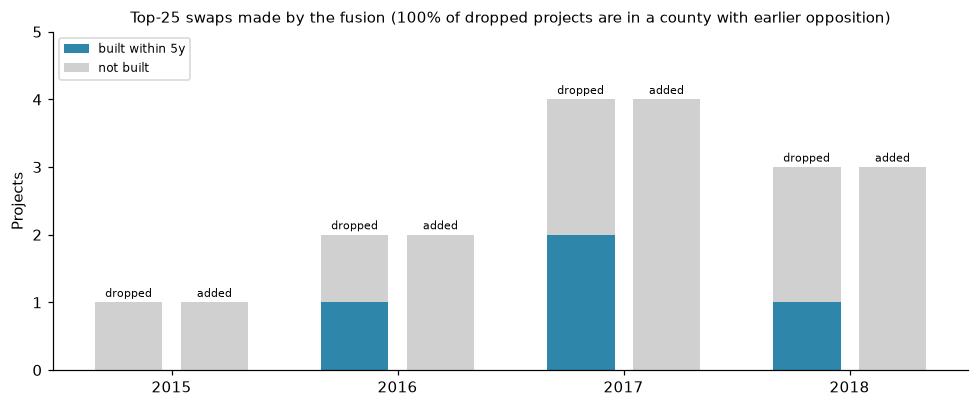

In [11]:
s = swaps.loc[YEARS]
xs = np.arange(len(YEARS))
w = 0.3
fig, ax = plt.subplots(figsize=(9, 3.8))
for off, side in [(-0.19, "dropped"), (0.19, "added")]:
    n, built = s["swaps"].to_numpy(), s[f"{side}: built"].to_numpy()
    ax.bar(xs + off, built, w, color="#2e86ab", label="built within 5y" if side == "dropped" else None)
    ax.bar(xs + off, n - built, w, bottom=built, color="#d0d0d0", label="not built" if side == "dropped" else None)
    for x, v in zip(xs + off, n):
        ax.text(x, v + 0.08, side, ha="center", fontsize=7.5)
ax.set_xticks(xs, YEARS)
ax.set_ylim(0, s["swaps"].max() + 1)
ax.set_ylabel("Projects")
share = s["dropped: from contested county"].sum() / max(s["swaps"].sum(), 1)
ax.set_title(f"Top-{K} swaps made by the fusion ({share:.0%} of dropped projects are in a county with earlier opposition)",
             fontsize=10)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "11_swap_analysis.png", bbox_inches="tight")
plt.show()

**This is the catch.** At the head of the list, the fusion makes 10 swaps over four cohorts:

- **Dropped:** all 10 projects it drops come from counties with earlier opposition, and **4 of them were built** within 5 years.
- **Added:** none of the 10 projects it adds were built.
- **Net:** the four top-25 shortlists hold 20 built projects with the tabular model alone and 16 after fusion.

**Why the AUC and the shortlist disagree.** AUC scores the order across the whole cohort. There, a blanket penalty on contested counties is right on average (5% vs. 9% built). But the contested-county projects that the tabular model put at the very top are exceptions: 4 of 10 were built, far above the 5% average for their group. The text penalty pushes them out anyway.

This rests on 10 projects, so it's a small sample. It's still a clear warning against letting the text score automatically re-rank the top of the list.

**For the fund:** the opposition record works best in two roles. It is a **portfolio-level prior**: expect fewer builds from contested counties. And it is a **diligence flag** on shortlisted projects: check what happened in that county. It should not automatically downgrade a project the tabular model ranks highly.

## Calibration: do the fused probabilities add up?

A fund uses the probabilities, not just the ranking, to size a portfolio. We compare the Brier score and the predicted vs. actual number of builds (`evaluate.calibration_ratio`), with the deciles below.

In [12]:
cal = pd.DataFrame({name: {"Brier": brier_score_loss(yy, s),
                           "predicted / actual builds": evaluate.calibration_ratio(yy, s)}
                    for name, s in [("Tabular only", scores[HEAD]["Tabular only"]), (BEST, sel)]
                    if np.nanmax(s) <= 1}).T
display(cal.round(4))
if BEST in cal.index:
    rel = evaluate.reliability_table(yy, sel, bins=10)
    display(rel.round(3))

,Brier,predicted / actual builds
Tabular only,0.079,1.016
Late fusion,0.079,1.020


,predicted,observed,n
bin,,,
0,0.023,0.023,349
1,0.049,0.046,349
2,0.061,0.080,349
3,0.070,0.057,349
4,0.080,0.072,349
5,0.089,0.086,349
6,0.099,0.097,349
7,0.113,0.146,349
8,0.131,0.109,349


**The fusion keeps the probabilities honest.** The Brier score is 0.079 for both models, and the predicted number of builds is within 2% of the actual number. The deciles track the observed rates, with some noise in the top deciles, where few projects were built.

This is partly by construction: the second stage refits the intercept each time, which recalibrates the probabilities.

## Showtime: the held-out test cohort (not run)

As in the other two notebooks, the 2019–2020 cohort is scored **once**, after the team agrees on the final setup. It needs the text model's test scores too, which notebook 02 writes only when its own `RUN_FINAL` is switched on. With the switch on, this cell fits the selected second stage on all 2015–2018 projects and scores 2019–2020.

In [13]:
RUN_FINAL = False   # The team agrees first (docs/HANDOFF.md). Do not flip this alone.

test_text = T[T["q_year"].between(*config.TEST_YEARS)]
if RUN_FINAL and len(test_text) and isinstance(ladder_rows(HEAD)[BEST], list):
    logit, y = _stage1(raw, projects, HEAD)
    Te = (test_text[["project_id", "q_year", "y", "has_text", "p_text"]]
          .merge(projects[["project_id"]].assign(**{f"logit_{HEAD}": logit}), on="project_id"))
    pt = Te["p_text"].clip(1e-6, 1 - 1e-6)
    Te["logit_text"] = np.log(pt / (1 - pt))
    Te["text_x_cov"] = Te["has_text"] * Te["logit_text"]
    out = {}
    for name in ["Tabular only", BEST]:
        cols = ladder_rows(HEAD)[name]
        out[name] = LogisticRegression(max_iter=1000).fit(V[cols], V["y"]).predict_proba(Te[cols])[:, 1]
    for name, s in out.items():
        print(name, {t: round(roc_auc_score(Te["y"][Te["q_year"] == t], s[Te["q_year"] == t]), 3)
                     for t in range(config.TEST_YEARS[0], config.TEST_YEARS[1] + 1)})
elif RUN_FINAL:
    print("No 2019–2020 text scores yet: run notebook 02 with RUN_FINAL = True first.")
else:
    n = projects["q_year"].between(*config.TEST_YEARS).sum()
    print(f"Test cohort ({config.TEST_YEARS[0]}–{config.TEST_YEARS[1]}, {n:,} projects) not scored.")

Test cohort (2019–2020, 3,184 projects) not scored.


## Summary

In [14]:
t_lasso, t_gb = tables["lasso"], tables["gb"]
g = gains.loc[(STAGE1[HEAD], BEST)]
r = roll.loc[(STAGE1[HEAD], BEST)] if (STAGE1[HEAD], BEST) in roll.index else None
display(Markdown(f"""
| Question | What late fusion shows (2015–2018 entries, {len(V):,} projects) |
|---|---|
| **How are the two models merged?** | Stacking: a logistic regression on the tabular and text log-odds, fit leave-one-year-out. Selected row: **{BEST}** |
| **Does the text add to the tabular model?** | A little. Mean within-year AUC goes from **{t_lasso.loc['Tabular only', 'mean within-year AUC']:.3f}** (LASSO alone) to **{t_lasso.loc[BEST, 'mean within-year AUC']:.3f}**, a gain of {g['within-year gain']:+.3f}, 95% CI {g['95% CI']}, positive in {g['P(gain > 0)']:.0%} of draws |
| **With gradient boosting as stage 1?** | {t_gb.loc['Tabular only', 'mean within-year AUC']:.3f} → {t_gb.loc[BEST, 'mean within-year AUC']:.3f} |
| **Strictly rolling second stage (2016–2018)?** | {"gain " + format(r['gain vs. tabular only'], '+.3f') if r is not None else "not applicable (no fitted weights)"} |
| **Text on its own?** | {t_lasso.loc['Text only', 'mean within-year AUC']:.3f}: close to a coin flip, as notebook 02 found. Its value only shows up next to the tabular score |
| **Where does it act?** | Only on the {cov.mean():.0%} of projects in a county with an earlier contested project; it pushes them down the ranking as a group |
| **And at the top of the list?** | It doesn't help there. Across the four top-{K} shortlists it swaps {int(swaps.loc['total', 'swaps'])} projects: the dropped ones were built {int(swaps.loc['total', 'dropped: built'])} times, the added ones {int(swaps.loc['total', 'added: built'])} times ({int(swaps.loc['total', 'top 25 built, tabular only'])} → {int(swaps.loc['total', f'top 25 built, {BEST.lower()}'])} built). Use the text as a diligence flag, not an automatic downgrade |
"""))


| Question | What late fusion shows (2015–2018 entries, 3,490 projects) |
|---|---|
| **How are the two models merged?** | Stacking: a logistic regression on the tabular and text log-odds, fit leave-one-year-out. Selected row: **Late fusion** |
| **Does the text add to the tabular model?** | A little. Mean within-year AUC goes from **0.632** (LASSO alone) to **0.643**, a gain of +0.011, 95% CI [+0.002, +0.019], positive in 99% of draws |
| **With gradient boosting as stage 1?** | 0.605 → 0.611 |
| **Strictly rolling second stage (2016–2018)?** | gain +0.006 |
| **Text on its own?** | 0.526: close to a coin flip, as notebook 02 found. Its value only shows up next to the tabular score |
| **Where does it act?** | Only on the 10% of projects in a county with an earlier contested project; it pushes them down the ranking as a group |
| **And at the top of the list?** | It doesn't help there. Across the four top-25 shortlists it swaps 10 projects: the dropped ones were built 4 times, the added ones 0 times (20 → 16 built). Use the text as a diligence flag, not an automatic downgrade |


**Caveats to keep in the pitch:**

1. **The effect is small.** About +0.01 AUC with the LASSO, +0.006 under a strictly rolling second stage, and close to zero with gradient boosting. The AUC gain also doesn't carry over to the top-25 shortlists.
2. **Dating.** These numbers use the re-dated paragraphs from `text.load_paragraphs()`. `stack.py` still uses the old dates and reports a larger flag gain. The team should quote the numbers here, and decide whether to update `stack.py`.
3. **Coverage and selection.** Only 10% of projects have a county record, and the Sabin reports cover disputes that were notable enough to be written up.
4. **Association, not cause.** Earlier opposition marks counties where projects struggle. It doesn't show that the opposition is the reason.
5. **Test cohort.** 2019–2020 is untouched. Scoring it needs the text model's test scores from notebook 02's `RUN_FINAL` run, then this notebook's `RUN_FINAL`.